In [1]:
from os.path import join
import numpy as np
import pandas as pd
import json
import h5py
import re
from bids import BIDSLayout
import os

import matplotlib.gridspec as gridspec
from matplotlib import pyplot as plt

import neurokit2 as nk
from scipy.signal import find_peaks
from scipy.stats import circmean, bootstrap
from functools import partial

import mne

from bids import BIDSLayout
layout = BIDSLayout('bids_dataset', derivatives = True)

In [2]:
# select subjects with acceptable EEG impedances
participants = layout.get(suffix = 'participants', extension = 'tsv')[0].get_df()
high_imp = participants.notes.str.contains('exceeded') == True
sub_nums = participants.participant_id.str.extract(r'sub-(\w+)')
good_subs = sub_nums[~high_imp].iloc[:, 0].to_list()
print('Excluded', sub_nums[high_imp][0].to_list())
print('%d subjects remaining.'%len(good_subs))

Excluded ['08', '19']
20 subjects remaining.


In [3]:
def process_ecg(physio, fs):
    '''
    computer cardiac phase for each sample, return that and the cleaned signal
    '''
    signals, info = nk.ecg_process(physio.ecg, sampling_rate = fs, method = 'neurokit')
    phase_type = signals['ECG_Phase_Ventricular'].copy()
    phase = signals['ECG_Phase_Completion_Ventricular'].copy()
    phase[phase_type == 1.] = (1 - phase[phase_type == 1.])*-1
    phase *= np.pi
    return signals.ECG_Clean, phase, ecg.time[info['ECG_R_Peaks']].to_numpy()

sub_means = []

for sub in good_subs:
    
    f = layout.get(subject = sub, task = 'streaming', extension = 'vhdr')[0]
    raw = mne.io.read_raw_brainvision(f.path)
    raw = raw.resample(1000.) 
    events = layout.get(subject = sub, task = 'streaming', suffix = 'events', extension = 'tsv')[0].get_df()

    ecg, ts = raw.get_data(picks = 'ecg', return_times = True)
    ecg = pd.DataFrame(dict(ecg = np.squeeze(ecg), time = ts))
    ecg['ecg_clean'], ecg['phase'], r_ts = process_ecg(ecg, raw.info['sfreq'])

    phases = []
    for i in range(events.shape[0]):
        t = events.onset.iloc[i]
        idx = np.argmin(np.abs(ecg.time - t))
        phases.append(ecg.phase.iloc[idx])
    events['phase'] = phases
    
    completion = []
    for i in range(events.shape[0]):
        t = events.onset.iloc[i]
        t0 = r_ts[r_ts < t][-1]
        t1 = r_ts[r_ts > t][0]
        completion.append(2*np.pi * (t - t0) / (t1 - t0))
    events['completion'] = completion

    A1 = events[events.tone_type == 'A'].reset_index().iloc[::2]
    B = events[events.tone_type == 'B']
    A2 = events[events.tone_type == 'A'].reset_index().iloc[1::2]

    sub_means.append(dict(
        subject = sub,
        phase_B_syst = circmean(B[B.trial_type == 'systole'].phase, high = np.pi, low = -np.pi),
        phase_B_dias = circmean(B[B.trial_type == 'diastole'].phase, high = np.pi, low = -np.pi),
        compl_B_syst = circmean(B[B.trial_type == 'systole'].completion),
        compl_B_dias = circmean(B[B.trial_type == 'diastole'].completion),
        phase_A1_syst = circmean(A1[A1.trial_type == 'systole'].phase, high = np.pi, low = -np.pi),
        phase_A1_dias = circmean(A1[A1.trial_type == 'diastole'].phase, high = np.pi, low = -np.pi),
        compl_A1_syst = circmean(A1[A1.trial_type == 'systole'].completion),
        compl_A1_dias = circmean(A1[A1.trial_type == 'diastole'].completion),
        phase_A2_syst = circmean(A2[A2.trial_type == 'systole'].phase, high = np.pi, low = -np.pi),
        phase_A2_dias = circmean(A2[A2.trial_type == 'diastole'].phase, high = np.pi, low = -np.pi),
        compl_A2_syst = circmean(A2[A2.trial_type == 'systole'].completion),
        compl_A2_dias = circmean(A2[A2.trial_type == 'diastole'].completion),
    ))
df = pd.DataFrame(sub_means)
df.head()

Extracting parameters from /home/johnv/repos/ecg-streaming-analysis/bids_dataset/sub-01/eeg/sub-01_task-streaming_eeg.vhdr...
Setting channel info structure...
Extracting parameters from /home/johnv/repos/ecg-streaming-analysis/bids_dataset/sub-02/eeg/sub-02_task-streaming_eeg.vhdr...
Setting channel info structure...
Extracting parameters from /home/johnv/repos/ecg-streaming-analysis/bids_dataset/sub-03/eeg/sub-03_task-streaming_eeg.vhdr...
Setting channel info structure...
Extracting parameters from /home/johnv/repos/ecg-streaming-analysis/bids_dataset/sub-04/eeg/sub-04_task-streaming_eeg.vhdr...
Setting channel info structure...
Extracting parameters from /home/johnv/repos/ecg-streaming-analysis/bids_dataset/sub-05/eeg/sub-05_task-streaming_eeg.vhdr...
Setting channel info structure...
Extracting parameters from /home/johnv/repos/ecg-streaming-analysis/bids_dataset/sub-06/eeg/sub-06_task-streaming_eeg.vhdr...
Setting channel info structure...
Extracting parameters from /home/johnv/r

,subject,phase_B_syst,phase_B_dias,compl_B_syst,compl_B_dias,phase_A1_syst,phase_A1_dias,compl_A1_syst,compl_A1_dias,phase_A2_syst,phase_A2_dias,compl_A2_syst,compl_A2_dias
0,01,-1.367598,1.566127,1.080133,4.065916,2.820362,0.434254,5.792860,2.507354,0.551798,2.666140,2.654098,5.621005
1,02,-1.893230,1.329862,0.962687,4.073296,2.644234,-0.005398,5.679685,2.508017,-0.036719,2.614390,2.531358,5.637680
2,03,-1.930022,1.255763,1.057657,4.099578,2.690690,-0.181418,5.765089,2.524950,-0.128834,2.609165,2.634814,5.674914
3,04,-0.978916,1.572420,1.105116,4.129135,2.835850,0.441913,5.821870,2.559407,0.576871,2.694568,2.677169,5.698662
4,05,-1.878692,1.277219,1.147228,3.957151,2.684273,-0.036501,5.817702,2.484084,0.155339,2.228137,2.754071,5.429225


In [4]:
for cond in ['syst', 'dias']:
    print(cond, circmean(df['phase_B_%s'%cond], high = np.pi, low = -np.pi))

syst -1.7379526241275374
dias 1.4380098794699148


In [5]:
for cond in ['syst', 'dias']:
    print(cond, circmean(df['compl_B_%s'%cond])/(2*np.pi))

syst 0.17646714741965344
dias 0.6771486455154596


In [6]:
for cond in ['syst', 'dias']:
    print(cond, circmean(df['compl_A1_%s'%cond])/(2*np.pi))

syst 0.9255441972625467
dias 0.4271342277289316


In [7]:
for cond in ['syst', 'dias']:
    print(cond, circmean(df['compl_A2_%s'%cond])/(2*np.pi))

syst 0.42753278774011116
dias 0.9270439459484342


In [8]:
cardiac_phases = df

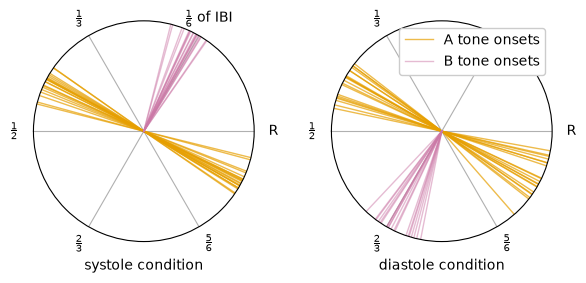

In [9]:
from cmap import Colormap, to_mpl
cm = to_mpl(Colormap('okabeito:okabeito'))
A_col = cm.colors[1]
B_col = cm.colors[-1] 

def plot_hist(df, ax, r_max, cond, phase_type, title):
    b = 10
    if phase_type == 'phase':
        theta_fill = np.linspace(np.pi, 2 * np.pi, 100)
        ax.fill_between(theta_fill, 0, r_max, color = 'gray', alpha = .5, label = 'ventricular systole')
    else:
        for i, rad in enumerate(df['%s_A1_%s'%(phase_type, cond)]):
            ax.plot([rad,rad], [0,r_max], color = A_col, label = 'A tone onsets' if i == 0 else None, linewidth = 1, alpha = .7)
        for rad in df['%s_A2_%s'%(phase_type, cond)]:
            ax.plot([rad,rad], [0,r_max], color = A_col, linewidth = 1, alpha = .7)
    for i, rad in enumerate(df['%s_B_%s'%(phase_type, cond)]):
        ax.plot([rad,rad], [0,r_max], color = B_col, label = 'B tone onsets' if i == 0 else None, linewidth = 1, alpha = .5)
    #ax.hist(df['%s_A1_%s'%(phase_type, cond)], bins = b, label = 'A', color = A_col, alpha = 1)
    #ax.hist(df['%s_B_%s'%(phase_type, cond)], bins = b, label = 'B', color = B_col, alpha = 1)
    #ax.hist(df['%s_A2_%s'%(phase_type, cond)], bins = b, color = A_col, alpha = 1)
    ax.set_rmax(r_max)
    if phase_type == 'phase':
        ticks = np.linspace(np.pi,  -np.pi, 8, endpoint = False)
        tick_labels = [
            r'R', 
            r'$\frac{3\pi}{4}$', 
            r'$\frac{\pi}{2}$', 
            r'$\frac{\pi}{4}$', 
            r'T',
            r'$-\frac{\pi}{4}$', 
            r'$-\frac{\pi}{2}$',
            r'$-\frac{3\pi}{4}$'
        ]
    else:
        ticks = np.linspace(np.pi,  -np.pi, 6, endpoint = False)
        if cond == 'syst':
            tick_labels = [
                r'$\frac{1}{2}$',
                r'$\frac{1}{3}$',
                r'$\frac{1}{6}$ of IBI',
                'R',
                r'$\frac{5}{6}$',
                r'$\frac{2}{3}$',
            ]
        else:
            tick_labels = [
                r'$\frac{1}{2}$',
                r'$\frac{1}{3}$',
                r'',
                'R',
                r'$\frac{5}{6}$',
                r'$\frac{2}{3}$',
            ]
    # set radian ticks
    ax.set_xticks(ticks)
    ax.set_xticklabels(tick_labels)
    ax.set_thetalim(-np.pi, np.pi)
    ax.set_xlabel(title)
    # adjust r ticks
    #ax.set_rlabel_position(90 + 45)
    tick_max = ax.get_rmax() - (ax.get_rmax() % 5)
    ticks = np.arange(5, tick_max + 1, step = 5) 
    ax.set_rticks(ticks)

r_max = 1

fig = plt.figure(figsize = (8.5*2, 8.5, 'cm'))
gs = gridspec.GridSpec(1, 2, wspace = .35)
ax = fig.add_subplot(gs[:, 0], projection = 'polar')
plot_hist(df, ax, r_max, 'syst', 'compl', 'systole condition')
ax = fig.add_subplot(gs[:, 1], projection = 'polar')
plot_hist(df, ax, r_max, 'dias', 'compl', 'diastole condition')
plt.legend(framealpha = 1, loc = 'upper right')
plt.savefig('tone-onsets.tif', dpi = 300, bbox_inches = 'tight')
plt.show()

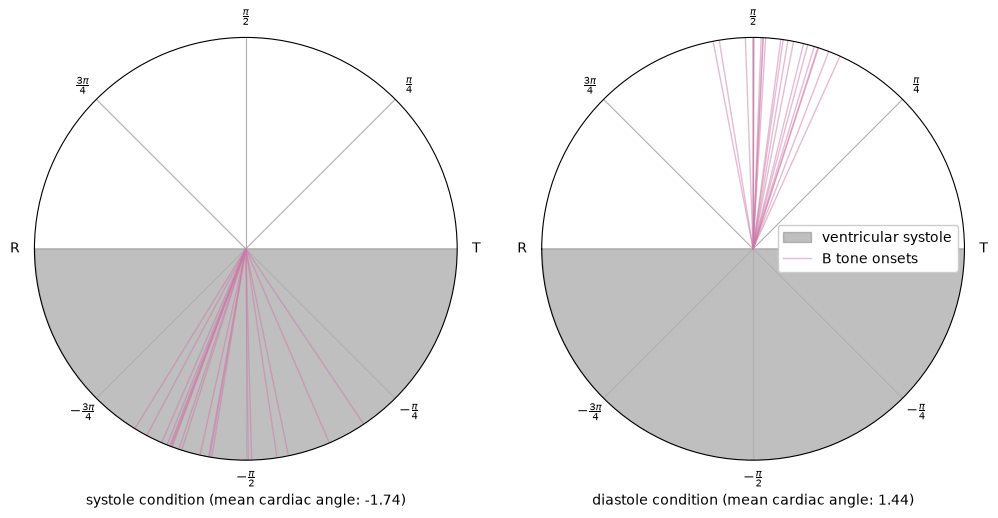

In [10]:
fig = plt.figure(figsize = (12, 6))
gs = gridspec.GridSpec(1, 2)
ax = fig.add_subplot(gs[:, 0], projection = 'polar')
plot_hist(df, ax, r_max, 'syst', 'phase', 'systole condition (mean cardiac angle: %.02f)'%circmean(df['phase_B_syst'], high = np.pi, low = -np.pi))
ax = fig.add_subplot(gs[:, 1], projection = 'polar')
plot_hist(df, ax, r_max, 'dias', 'phase', 'diastole condition (mean cardiac angle: %.02f)'%circmean(df['phase_B_dias']))
plt.legend(framealpha = 1)
plt.show()

In [11]:
df['phase_B_syst'].min(), df['phase_B_syst'].max()

(np.float64(-2.123546793296506), np.float64(-0.9789161205500339))

In [12]:
df['phase_B_dias'].min(), df['phase_B_dias'].max()

(np.float64(1.1469390368286803), np.float64(1.7610036332726242))

In [32]:
cardiac_phases['compl_B_syst'].min()/(2*np.pi), cardiac_phases['compl_B_syst'].max()/(2*np.pi)

(np.float64(0.15321632152002773), np.float64(0.21060126001302668))

In [33]:
cardiac_phases['compl_A1_syst'].min()/(2*np.pi), cardiac_phases['compl_A1_syst'].max()/(2*np.pi)

(np.float64(0.9039499015302886), np.float64(0.9615118705267627))

In [34]:
cardiac_phases['compl_A2_syst'].min()/(2*np.pi), cardiac_phases['compl_A2_syst'].max()/(2*np.pi)

(np.float64(0.4025265111275812), np.float64(0.4603331223778738))

In [35]:
cardiac_phases['compl_B_dias'].min()/(2*np.pi), cardiac_phases['compl_B_dias'].max()/(2*np.pi)

(np.float64(0.6298001588700608), np.float64(0.7192887598395359))

# Random slopes model

In [13]:
import polars as pl
from pymer4.models import glmer
import statsmodels.api as sm
from scipy import stats

In [14]:
# select subjects with acceptable EEG impedances
participants = layout.get(suffix = 'participants', extension = 'tsv')[0].get_df()
high_imp = participants.notes.str.contains('exceeded') == True
sub_nums = participants.participant_id.str.extract(r'sub-(\w+)')
good_subs = sub_nums[~high_imp].iloc[:, 0].to_list()
print('Excluded', sub_nums[high_imp][0].to_list())
print('%d subjects remaining.'%len(good_subs))

fs = layout.get(subject = good_subs, task = 'streaming', suffix = 'events', extension = 'tsv')
events = [f.get_df() for f in fs]
for ev, f in zip(events, fs):
    ev.insert(0, 'subject', f.entities['subject']) 
events = pd.concat(events)
trials = events[events.tone_num == 1] # so we don't over count trials b/c multiple tones
trials = trials.reset_index(drop = True)
trials['response'] = trials.response == 'streaming'
trials.head()

Excluded ['08', '19']
20 subjects remaining.


,subject,onset,duration,trial_num,trial_type,tone_num,tone_type,frequency,response
0,01,190.3276,0.132501,1,systole,1,A,1578.567003,False
1,01,208.5275,0.118755,2,diastole,1,A,1578.567003,False
2,01,221.4114,0.117513,3,systole,1,A,2180.022500,False
3,01,236.8508,0.123097,4,diastole,1,A,2180.022500,False
4,01,254.5302,0.138158,5,diastole,1,A,1987.945240,False


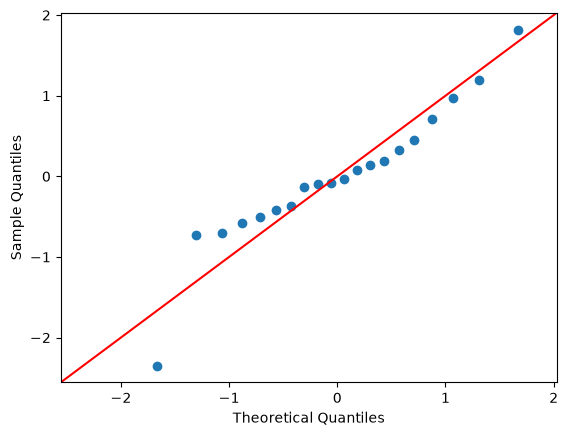

In [15]:
# fit model with random intercepts AND random slopes
slopes = glmer(
    'response ~ trial_type + (1 + trial_type | subject)', 
    data = pl.DataFrame(trials),
    family = 'binomial', link = 'logit'
)
slopes.set_factors('trial_type')
slopes.fit(conf_level = .95)

# extract random slopes and put them on normal scale for Q-Q plot
ranef = slopes.ranef['trial_type_L'].to_numpy()
sd = slopes.ranef_var['estimate'].to_numpy()[slopes.ranef_var['term'] == 'sd__trial_type.L'][0]
ranef = ranef/sd # put on standard scale

# now check normality assumption of random slopes model
sm.qqplot(ranef, line = '45')
plt.show()

Looks like the participant-level slopes substantially deviate from normality, violating the assumptions of a random slopes model. It is likely to be driven by that outlier, so lets see if removing them fixes it.

In [16]:
# Calculate Median and MAD
median = np.median(ranef)
mad = stats.median_abs_deviation(ranef)

# Calculate Modified Z-scores
# 0.6745 scales the MAD to replicate standard deviation properties
modified_z_scores = 0.6745 * (ranef - median) / mad

# Filter outliers
outliers = np.atleast_1d(np.squeeze(np.argwhere(np.abs(modified_z_scores) > 3.5)))
outliers =  [good_subs[i] for i in outliers]
outliers

['02']

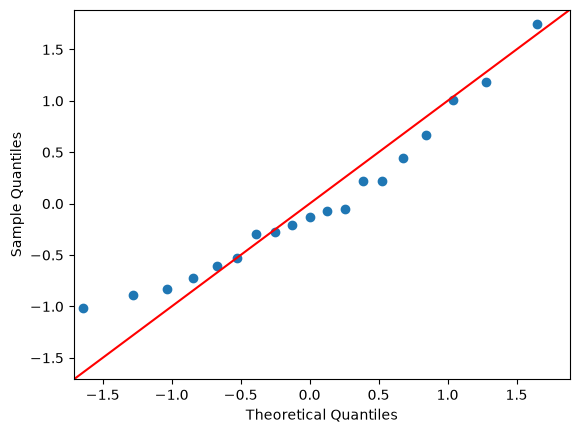

In [17]:
slopes = glmer(
    'response ~ trial_type + (1 + trial_type | subject)', 
    data = pl.DataFrame(trials[~trials.subject.isin(outliers)]),
    family = 'binomial', link = 'logit'
)
slopes.set_factors('trial_type')
slopes.fit(conf_level = .95)


# extract random slopes and put them on normal scale for Q-Q plot
ranef = slopes.ranef['trial_type_L'].to_numpy()
sd = slopes.ranef_var['estimate'].to_numpy()[slopes.ranef_var['term'] == 'sd__trial_type.L'][0]
ranef = ranef/sd # put on standard scale

# now check normality assumption of random slopes model
sm.qqplot(ranef, line = '45')
plt.show()

Okay, that helped a little. What does the model say?

In [18]:
slopes.summary()

GT(_tbl_data=shape: (7, 10)
┌────────────────┬───────────────┬───────────┬───────────┬───┬───────────┬──────┬──────────┬───────┐
│ rfx            ┆ param         ┆ estimate  ┆ conf_low  ┆ … ┆ z_stat    ┆ df   ┆ p_value  ┆ stars │
│ ---            ┆ ---           ┆ ---       ┆ ---       ┆   ┆ ---       ┆ ---  ┆ ---      ┆ ---   │
│ str            ┆ str           ┆ f64       ┆ f64       ┆   ┆ f64       ┆ f64  ┆ str      ┆ str   │
╞════════════════╪═══════════════╪═══════════╪═══════════╪═══╪═══════════╪══════╪══════════╪═══════╡
│ subject-sd     ┆ (Intercept)   ┆ 0.460588  ┆ null      ┆ … ┆ null      ┆ null ┆ null     ┆ null  │
│ subject-sd     ┆ trial_type    ┆ 0.25674   ┆ null      ┆ … ┆ null      ┆ null ┆ null     ┆ null  │
│ subject-cor    ┆ (Intercept)   ┆ -0.617059 ┆ null      ┆ … ┆ null      ┆ null ┆ null     ┆ null  │
│ null           ┆ null          ┆ null      ┆ null      ┆ … ┆ null      ┆ null ┆ null     ┆ null  │
│ Fixed Effects: ┆ null          ┆ null      ┆ null      ┆ … ┆ null      ┆ null ┆ null     ┆ null  │
│ null           ┆ (Intercept)   ┆ -0.422969 ┆ -0.721482 ┆ … ┆ -2.777115 ┆ inf  ┆ 0.005484 ┆ **    │
│ null           ┆ trial_typesys ┆ 0.306061  ┆ 0.056236  ┆ … ┆ 2.401157  ┆ inf  ┆ 0.01634  ┆ *     │
│                ┆ tole          ┆           ┆           ┆   ┆           ┆      ┆          ┆       │
└────────────────┴───────────────┴───────────┴───────────┴───┴───────────┴──────┴──────────┴───────┘, _body=<great_tables._gt_data.Body object at 0x7ff25aca5370>, _boxhead=Boxhead([ColInfo(var='rfx', type=<ColInfoTypeEnum.default: 1>, column_label='Random Effects:', column_align='left', column_width=None), ColInfo(var='param', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='left', column_width=None), ColInfo(var='estimate', type=<ColInfoTypeEnum.default: 1>, column_label='Estimate', column_align='right', column_width=None), ColInfo(var='conf_low', type=<ColInfoTypeEnum.default: 1>, column_label='CI-low', column_align='right', column_width=None), ColInfo(var='conf_high', type=<ColInfoTypeEnum.default: 1>, column_label='CI-high', column_align='right', column_width=None), ColInfo(var='std_error', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None), ColInfo(var='z_stat', type=<ColInfoTypeEnum.default: 1>, column_label='Z-stat', column_align='right', column_width=None), ColInfo(var='df', type=<ColInfoTypeEnum.default: 1>, column_label='df', column_align='right', column_width=None), ColInfo(var='p_value', type=<ColInfoTypeEnum.default: 1>, column_label='p', column_align='left', column_width=None), ColInfo(var='stars', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x7ff259fc30b0>, _spanners=Spanners([]), _heading=Heading(title='Formula: glmer(response~trial_type+(1+trial_type|subject))', subtitle=Md(text='Family: *binomial (link: *logit*)*  \n            Number of observations: *1875*  \n            Confidence intervals: *parametric*  \n            ---------------------  \n            Log-likelihood: *-1250*  \n            AIC: *2510* | BIC: *2538*  \n            Residual error: *1.0*  \n        '), preheader=None), _stubhead=None, _source_notes=[Md(text='Signif. codes: *0 *** 0.001 ** 0.01 * 0.05 . 0.1*')], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=['param'], rows=None, mask=None), grpname=None, colname='param', rownum=0, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style='italic', weight=None, stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=['param'], rows=None, mask=None), grpname=None, colname='param', rownum=1, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style='italic', weight=None, stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=['param'], rows=No

But do we even need random slopes?

In [19]:
mod = glmer( # interacts only model
    'response ~ trial_type + (1 | subject)', 
    data = pl.DataFrame(trials[~trials.subject.isin(outliers)]),
    family = 'binomial', link = 'logit'
)
mod.set_factors('trial_type')
mod.fit(summary = True, conf_level = .95)

GT(_tbl_data=shape: (5, 10)
┌────────────┬───────────────────┬───────────┬───────────┬───┬───────────┬──────┬──────────┬───────┐
│ rfx        ┆ param             ┆ estimate  ┆ conf_low  ┆ … ┆ z_stat    ┆ df   ┆ p_value  ┆ stars │
│ ---        ┆ ---               ┆ ---       ┆ ---       ┆   ┆ ---       ┆ ---  ┆ ---      ┆ ---   │
│ str        ┆ str               ┆ f64       ┆ f64       ┆   ┆ f64       ┆ f64  ┆ str      ┆ str   │
╞════════════╪═══════════════════╪═══════════╪═══════════╪═══╪═══════════╪══════╪══════════╪═══════╡
│ subject-sd ┆ (Intercept)       ┆ 0.453943  ┆ null      ┆ … ┆ null      ┆ null ┆ null     ┆ null  │
│ null       ┆ null              ┆ null      ┆ null      ┆ … ┆ null      ┆ null ┆ null     ┆ null  │
│ Fixed      ┆ null              ┆ null      ┆ null      ┆ … ┆ null      ┆ null ┆ null     ┆ null  │
│ Effects:   ┆                   ┆           ┆           ┆   ┆           ┆      ┆          ┆       │
│ null       ┆ (Intercept)       ┆ -0.408766 ┆ -0.652758 ┆ … ┆ -3.283563 ┆ inf  ┆ 0.001025 ┆ **    │
│ null       ┆ trial_typesystole ┆ 0.290207  ┆ 0.102866  ┆ … ┆ 3.036146  ┆ inf  ┆ 0.002396 ┆ **    │
└────────────┴───────────────────┴───────────┴───────────┴───┴───────────┴──────┴──────────┴───────┘, _body=<great_tables._gt_data.Body object at 0x7ff2594b7fe0>, _boxhead=Boxhead([ColInfo(var='rfx', type=<ColInfoTypeEnum.default: 1>, column_label='Random Effects:', column_align='left', column_width=None), ColInfo(var='param', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='left', column_width=None), ColInfo(var='estimate', type=<ColInfoTypeEnum.default: 1>, column_label='Estimate', column_align='right', column_width=None), ColInfo(var='conf_low', type=<ColInfoTypeEnum.default: 1>, column_label='CI-low', column_align='right', column_width=None), ColInfo(var='conf_high', type=<ColInfoTypeEnum.default: 1>, column_label='CI-high', column_align='right', column_width=None), ColInfo(var='std_error', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None), ColInfo(var='z_stat', type=<ColInfoTypeEnum.default: 1>, column_label='Z-stat', column_align='right', column_width=None), ColInfo(var='df', type=<ColInfoTypeEnum.default: 1>, column_label='df', column_align='right', column_width=None), ColInfo(var='p_value', type=<ColInfoTypeEnum.default: 1>, column_label='p', column_align='left', column_width=None), ColInfo(var='stars', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x7ff2594b4b60>, _spanners=Spanners([]), _heading=Heading(title='Formula: glmer(response~trial_type+(1|subject))', subtitle=Md(text='Family: *binomial (link: *logit*)*  \n            Number of observations: *1875*  \n            Confidence intervals: *parametric*  \n            ---------------------  \n            Log-likelihood: *-1253*  \n            AIC: *2512* | BIC: *2528*  \n            Residual error: *1.0*  \n        '), preheader=None), _stubhead=None, _source_notes=[Md(text='Signif. codes: *0 *** 0.001 ** 0.01 * 0.05 . 0.1*')], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=['param'], rows=None, mask=None), grpname=None, colname='param', rownum=0, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style='italic', weight=None, stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=['param'], rows=None, mask=None), grpname=None, colname='param', rownum=1, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style='italic', weight=None, stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=['param'], rows=None, mask=None), grpname=None, colname='param', rownum=2, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style='italic', weight=None, stretch=None, decorate=None, tra

The intercept-only model has a much better BIC. Slightly worse AIC though, so let's check with the likelihood ratio test (which prefers the same models AIC does) whether that difference is worth paying attention to.

In [20]:
from pymer4.models import compare
compare(slopes, mod, test = 'LRT')

GT(_tbl_data=shape: (2, 10)
┌─────────────┬─────────────┬──────────────┬──────┬───┬─────┬────────────┬───────┬─────┐
│ AIC         ┆ BIC         ┆ logLik       ┆ npar ┆ … ┆ Df  ┆ Pr(>Chisq) ┆ stars ┆ ids │
│ ---         ┆ ---         ┆ ---          ┆ ---  ┆   ┆ --- ┆ ---        ┆ ---   ┆ --- │
│ f64         ┆ f64         ┆ f64          ┆ i64  ┆   ┆ f64 ┆ str        ┆ str   ┆ i64 │
╞═════════════╪═════════════╪══════════════╪══════╪═══╪═════╪════════════╪═══════╪═════╡
│ 2510.327588 ┆ 2538.009408 ┆ -1250.163794 ┆ 3    ┆ … ┆ 0.0 ┆            ┆       ┆ 1   │
│ 2512.169884 ┆ 2528.778976 ┆ -1253.084942 ┆ 5    ┆ … ┆ 2.0 ┆ 0.0539     ┆ .     ┆ 2   │
└─────────────┴─────────────┴──────────────┴──────┴───┴─────┴────────────┴───────┴─────┘, _body=<great_tables._gt_data.Body object at 0x7ff2594b4050>, _boxhead=Boxhead([ColInfo(var='ids', type=<ColInfoTypeEnum.stub: 2>, column_label='', column_align='right', column_width=None), ColInfo(var='AIC', type=<ColInfoTypeEnum.default: 1>, column_label='AIC', column_align='right', column_width=None), ColInfo(var='BIC', type=<ColInfoTypeEnum.default: 1>, column_label='BIC', column_align='right', column_width=None), ColInfo(var='logLik', type=<ColInfoTypeEnum.default: 1>, column_label='logLik', column_align='right', column_width=None), ColInfo(var='npar', type=<ColInfoTypeEnum.default: 1>, column_label='npar', column_align='right', column_width=None), ColInfo(var='-2*log(L)', type=<ColInfoTypeEnum.default: 1>, column_label='-2*log(L)', column_align='right', column_width=None), ColInfo(var='Chisq', type=<ColInfoTypeEnum.default: 1>, column_label='Chisq', column_align='right', column_width=None), ColInfo(var='Df', type=<ColInfoTypeEnum.default: 1>, column_label='Df', column_align='right', column_width=None), ColInfo(var='Pr(>Chisq)', type=<ColInfoTypeEnum.default: 1>, column_label='Pr(>Chisq)', column_align='left', column_width=None), ColInfo(var='stars', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x7ff25a077e60>, _spanners=Spanners([]), _heading=Heading(title='Analysis of Deviance Table', subtitle=Md(text='Model 1: glmer(response~trial_type+(1+trial_type|subject))   \nModel 2: glmer(response~trial_type+(1|subject))   \n'), preheader=None), _stubhead=None, _source_notes=[Md(text='Signif. codes: *0 *** 0.001 ** 0.01 * 0.05 . 0.1*')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7ff2594b7770>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7ff25af53bf0>, <great_tables._gt_data.FormatInfo object at 0x7ff2594b6e70>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x7ff2594b4500>], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_fo

Not quite significant, but close. Maybe if the models gave different answers with/without random slopes, I would be worried. But they don't, so I'm not!

# Checking EEG data for cardiac artifact

In [21]:
import arviz as az
from scipy.stats import bootstrap

def calc_boot_mean_CIs(x, conf_level = .95):
    '''
    finds smallest intervals containing conf_level proportion
    of the bootstrap samples (i.e. highest density interval)
    '''
    import arviz as az
    try: # deal with multiple arviz versions
        ci = az.hdi(x, prob = conf_level)
    except:
        ci = az.hdi(x, hdi_prob = conf_level)
    return ci

In [22]:
df = pd.concat([f.get_df() for f in layout.get(subject = good_subs, scope = 'extract_ffr_fake', desc = '500Hz')])
systole = df.amplitude[df.condition == 'systole'].to_numpy()
diastole = df.amplitude[df.condition == 'diastole'].to_numpy()

In [23]:
boot = bootstrap([systole], np.mean, confidence_level = 0.95, n_resamples = 10000, random_state = 0)
boot.bootstrap_distribution.mean(), calc_boot_mean_CIs(boot.bootstrap_distribution, .95)

(np.float64(-1.3817213349134307), array([-2.56251117, -0.15347794]))

In [24]:
boot = bootstrap([diastole], np.mean, confidence_level = 0.95, n_resamples = 10000, random_state = 0)
boot.bootstrap_distribution.mean(), calc_boot_mean_CIs(boot.bootstrap_distribution, .95)

(np.float64(-0.32688844788236193), array([-1.61979101,  0.90802314]))

In [25]:
boot = bootstrap([systole - diastole], np.mean, confidence_level = 0.95, n_resamples = 10000, random_state = 0)
boot.bootstrap_distribution.mean(), calc_boot_mean_CIs(boot.bootstrap_distribution, .95)

(np.float64(-1.0548328870310688), array([-3.12878866,  0.79234943]))

In [26]:
from scipy.interpolate import interp1d

freqs = np.linspace(200, 2000, 2000-200)

def get_sub_power(sub, cond):
    '''
    interpolates power (dB) at common frequency values for all subjects
    (because the exact frequencies at which power was computed for each
    participant depended on the epoch duration, which depended on the 
    stimulus length, which depended on their individual heart rate!)
    '''
    pow_df = layout.get(subject = sub, desc = cond, suffix = 'power', scope = 'extract_ffr_fake')[0].get_df()
    f = interp1d(pow_df.freq, pow_df.dB, fill_value = 'extrapolate')
    dB = f(freqs)
    return dB


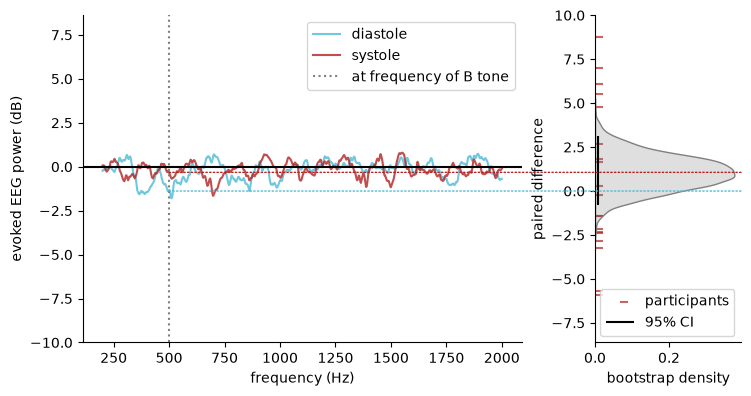

In [27]:
import seaborn as sns

# flips conditions, since we're looking at EEG during systole during diastole condition and vice versa
df = pd.concat([f.get_df() for f in layout.get(subject = good_subs, scope = 'extract_ffr_fake', desc = '500Hz')])
systole = df.amplitude[df.condition == 'diastole'].to_numpy()
diastole = df.amplitude[df.condition == 'systole'].to_numpy()
boot = bootstrap([systole - diastole], np.mean, confidence_level = 0.95, n_resamples = 10000, random_state = 0)
boot.bootstrap_distribution.mean(), calc_boot_mean_CIs(boot.bootstrap_distribution, .95)

syst_col = 'firebrick'
diast_col = '#4DBBD5FF'

fig, axs = plt.subplots(1, 2, width_ratios = (3, 1), gridspec_kw = dict(wspace = .25), figsize = (8.5, 8.5/2))

subs = good_subs
dB_systole = np.stack([get_sub_power(sub, 'diastole') for sub in subs]).mean(0)
dB_syst_std = 1.96*np.stack([get_sub_power(sub, 'diastole') for sub in subs]).std(0)
dB_diastole = np.stack([get_sub_power(sub, 'systole') for sub in subs]).mean(0)
dB_dias_std = 1.96*np.stack([get_sub_power(sub, 'systole') for sub in subs]).std(0)
axs[0].plot(freqs, dB_diastole, label = 'diastole', color = diast_col, alpha = .8)
axs[0].plot(freqs, dB_systole, label = 'systole', color = syst_col, alpha = .8)
axs[0].set_xlabel('frequency (Hz)')
axs[0].set_ylabel('evoked EEG power (dB)')
axs[0].axvline(500, linestyle = 'dotted', color = 'gray', label = 'at frequency of B tone')
axs[0].legend(loc = 'upper right')
axs[0].axhline(0, color = 'black')
y_offset = 10
axs[0].set_ylim(-10, diastole.mean() + y_offset)
axs[0].spines[['top', 'right']].set_visible(False)

sns.kdeplot(y = boot.bootstrap_distribution, color = 'grey', fill = True, ax = axs[1])
axs[1].set_xlabel('bootstrap density')
axs[1].set_ylabel('paired difference')
axs[1].set_ylim(-10 - diastole.mean(), y_offset)
axs[1].scatter(np.zeros_like(systole), systole-diastole, marker = 1, zorder = 0, color = syst_col, alpha = .7, label = 'participants')
axs[1].vlines(.0075, boot.confidence_interval[0], boot.confidence_interval[1], color = 'black', label = '95% CI')
axs[1].spines[['top', 'right']].set_visible(False)
axs[1].legend(loc = 'lower right')

from matplotlib.patches import ConnectionPatch

xlim = axs[1].get_xlim()
con = ConnectionPatch(
    xyA = (500, diastole.mean()), 
    xyB = (xlim[1], 0),      
    coordsA = 'data',       
    coordsB = 'data',       
    axesA = axs[0],    
    axesB = axs[1], 
    linestyle = 'dotted',
    color = diast_col,
    zorder = 1000,
    #linewidth = .2
)
fig.add_artist(con)
con = ConnectionPatch(
    xyA = (500, systole.mean()), 
    xyB = (xlim[1], (systole - diastole).mean()),      
    coordsA = 'data',       
    coordsB = 'data',       
    axesA = axs[0],    
    axesB = axs[1], 
    linestyle = 'dotted',
    color = syst_col,
    zorder = 1000,
    #linewidth = .2
)
fig.add_artist(con)
plt.savefig('fake_ffr.jpeg', dpi = 300, bbox_inches = 'tight')
plt.show()